# Phase 3: PHI fingerprint for free text and private tags

**Goal:** keep the useful text (descriptions, protocol names, vendor text tags) and remove only the parts that
identify the patient.

**Idea (the novel part):** the best detector of a patient's leaked identity is the patient's own identity.
Before cleaning, we read each patient's identifiers from the fields where identity is known to live (name, IDs,
dates, address, phone, institution, devices), expand them into all the ways they can be written, and search for
them in every text value. (Optional site level: also the full names, addresses, phones and long IDs of all other
patients of the same data; tested in the ablation, off by default.) A small set of generic patterns (SSN, phone, e-mail, dates, "Dr. X", site codes) is the backup.
A data-driven guard stops ordinary words from being removed: a word that appears in the text of many other
patients is not an identifier.

**Ablation study:** we compare, on the full validation set with the official scorer,
1. rules only (Phase 2),
2. rules + generic patterns,
3. rules + NER (spaCy, as many existing tools do) + the same patterns,
4. rules + fingerprint with exact values only,
5. rules + fingerprint with variants, no patterns,
6. **FP-DeID: fingerprint + variants + patterns + guard** (final),
7. FP-DeID without the common-word guard,
8. FP-DeID **with** site-level entries (names/addresses/IDs of all other patients), an option that is off by default.

Pass criteria (docs/PLAN.md): score ≥ 99% on validation; 0 residual fingerprint hits; free-text and private-tag
leaks listed with causes; fingerprint ≥ NER on both privacy and utility; 100% of redactions explainable;
extra time ≤ 20 ms per file.

In [1]:
import os
import json
import time
import shutil
import pickle
import collections

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fpdeid import paths
from fpdeid import engine
from fpdeid import fingerprint
from fpdeid import ner_baseline
from fpdeid import scoring
from fpdeid import validity
from fpdeid import checks

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

phase_results = os.path.join(paths.RESULTS, "phase3")
os.makedirs(phase_results, exist_ok=True)
scorer_out = os.path.join(paths.DERIVED, "scorer_runs")

file_table = pd.read_csv(os.path.join(paths.DERIVED, "validation_file_table.csv"), dtype=str)
all_files = file_table["path"].tolist()
answer_db = os.path.join(paths.VALIDATION_ANSWER_DIR, "MIDI-B-Answer-Key-Validation.db")
policy_path = os.path.join(paths.CONFIGS, "policy.yaml")
print("files:", len(all_files))

files: 23921


## 1. Build the fingerprints (one pass over all headers)

In [2]:
start = time.time()
final_settings = engine.Policy(policy_path, paths.VALIDATION_UID_MAP, paths.VALIDATION_PATIENT_MAP)
fingerprints, common_words = fingerprint.build_all(all_files, workers=16, common_share=final_settings.common_word_share,
                                                   use_site=final_settings.site_level)
build_seconds = time.time() - start
print("patients:", len(fingerprints), "| built in", round(build_seconds, 1), "s")
print("ordinary words that are never removed on their own:", len(common_words))
print("examples:", sorted(common_words)[:25])

patients: 216 | built in 14.6 s
ordinary words that are never removed on their own: 499
examples: ['AAH', 'AAI', 'ABDOMEN', 'ABSENT', 'ACHIEVA', 'ACP', 'ACQ', 'ACQU', 'ACQUISITION', 'ACRIN', 'ACTION', 'ACTIVITY', 'ADAC', 'ADMITTED', 'ADS', 'ADULT', 'ADVANCE', 'AFRICAN', 'AGE', 'AGFA', 'ALGO', 'ALGORITHM', 'AMERICAN', 'AND', 'ANNOTATION']


In [3]:
sizes = []
for patient, fp in fingerprints.items():
    counts = collections.Counter(category for variant, category, source in fp.entries)
    counts["patient"] = patient
    counts["total"] = len(fp.entries)
    sizes.append(counts)
size_table = pd.DataFrame(sizes).fillna(0)
size_table.drop(columns=["patient"]).describe().loc[["mean", "min", "max"]].round(1)

,date,name,device,id,total,address,institution
mean,46.2,17.7,1.1,4.2,71.3,1.3,0.8
min,30.0,8.0,0.0,3.0,43.0,0.0,0.0
max,165.0,49.0,8.0,13.0,220.0,11.0,6.0


In [4]:
# one fingerprint as an example (synthetic data)
example_patient = "2004456760"
example = pd.DataFrame(fingerprints[example_patient].entries, columns=["variant", "category", "source"])
example.groupby("category").head(4)

,variant,category,source
0,"1699 S 200 E Salt Lake City, UT 84115",address,InstitutionAddress
1,"900 N 400 W Salt Lake City, UT 84103",address,PatientAddress
2,1699 S 200 E Salt Lake City,address,InstitutionAddress
3,900 N 400 W Salt Lake City,address,PatientAddress
4,Burke-Perkins Clinic,institution,InstitutionName
5,"December 9, 2012",date,StudyDate
6,"October 28, 1956",date,PatientBirthDate
7,"December 4, 2012",date,DateOfLastCalibration
8,9 December 2012,date,StudyDate
9,20121209E640506,id,AccessionNumber


## 2. Ablation study (full validation set, official scorer)

In [5]:
def make_policy(path):
    return engine.Policy(path, paths.VALIDATION_UID_MAP, paths.VALIDATION_PATIENT_MAP)


def variant_policy(name):
    """Return the Policy object for one ablation variant."""
    if name == "1 rules only (Phase 2)":
        return make_policy(os.path.join(paths.CONFIGS, "policy_phase2.yaml"))
    policy = make_policy(policy_path)
    if name == "2 rules + generic patterns":
        policy.set_fingerprints({})
    elif name == "3 rules + NER + patterns":
        policy.set_fingerprints({})
        policy.set_shared_cleaner(ner_baseline.NerCleaner())
    elif name == "4 rules + fingerprint (exact values)":
        fps, _ = fingerprint.build_all(all_files, workers=16, use_variants=False, use_patterns=False, use_site=False)
        policy.set_fingerprints(fps)
    elif name == "5 rules + fingerprint (variants, no patterns)":
        fps, _ = fingerprint.build_all(all_files, workers=16, use_patterns=False, use_site=False)
        policy.set_fingerprints(fps)
    elif name == "6 FP-DeID (fingerprint + patterns + guard)":
        policy.set_fingerprints(fingerprints)
    elif name == "7 FP-DeID without word guard":
        fps, _ = fingerprint.build_all(all_files, workers=16, use_guard=False, use_site=False)
        policy.set_fingerprints(fps)
    elif name == "8 FP-DeID with site level":
        fps, _ = fingerprint.build_all(all_files, workers=16, use_site=True)
        policy.set_fingerprints(fps)
    return policy


VARIANTS = [
    "1 rules only (Phase 2)",
    "2 rules + generic patterns",
    "3 rules + NER + patterns",
    "4 rules + fingerprint (exact values)",
    "5 rules + fingerprint (variants, no patterns)",
    "6 FP-DeID (fingerprint + patterns + guard)",
    "7 FP-DeID without word guard",
    "8 FP-DeID with site level",
]

In [6]:
# free-text / private-text checks: the fields the fingerprint works on
def text_field_metrics(results):
    """Leaks and over-cleaning only in free-text and private text fields."""
    text_actions = results["action"].isin(["<text_removed>", "<text_retained>"])
    is_private = results["tag_name"].fillna("").str.startswith("<[") | (results["tag_name"] == "<Private tag data>")
    is_free_text = results["tag_name"].isin(FREE_TEXT_NAMES)
    part = results[text_actions & (is_private | is_free_text)]
    passed = part["check_passed"].fillna(0).astype(float)

    removed = part["action"] == "<text_removed>"
    retained = part["action"] == "<text_retained>"
    metrics = {}
    metrics["text PHI checks"] = int(removed.sum())
    metrics["text leaks"] = int(removed.sum() - passed[removed].sum())
    metrics["text PHI recall %"] = round(100 * passed[removed].mean(), 3)
    metrics["text keep checks"] = int(retained.sum())
    metrics["text over-cleaned"] = int(retained.sum() - passed[retained].sum())
    metrics["text kept %"] = round(100 * passed[retained].mean(), 3)
    recall = passed[removed].mean()
    kept = passed[retained].mean()
    metrics["F2 (recall x2, kept)"] = round(100 * 5 * recall * kept / (4 * kept + recall), 3)
    return metrics


table = pd.read_csv(os.path.join(paths.CONFIGS, "ps315_table_e1_1.csv"), dtype=str).fillna("")
FREE_TEXT_NAMES = ["<" + name + ">" for name in table[table["clean_descriptors"] == "C"]["name"]]
FREE_TEXT_NAMES = FREE_TEXT_NAMES + ["<Text Value>"]

In [7]:
ablation = {}
saved_ablation = os.path.join(paths.DERIVED, "phase3_ablation.pkl")
if os.path.exists(saved_ablation):
    with open(saved_ablation, "rb") as f:
        ablation = pickle.load(f)

for name in VARIANTS:
    if name in ablation:
        print("reused:", name)
        continue
    print("=====", name)
    run_name = "phase3_" + name.split(" ")[0]

    if name.startswith("1 "):
        db_path = os.path.join(scorer_out, "phase2", "validation_results.db")
        seconds = np.nan
    else:
        policy = variant_policy(name)
        out_folder = os.path.join(paths.OUTPUTS, run_name)
        shutil.rmtree(out_folder, ignore_errors=True)
        start = time.time()
        run_table = engine.run(all_files, out_folder, policy, workers=16)
        seconds = time.time() - start
        print("cleaned in", round(seconds, 1), "s, errors:", (run_table["error"] != "").sum())
        db_path = scoring.run_official_scorer(run_name, out_folder, answer_db, paths.VALIDATION_UID_MAP,
                                              paths.VALIDATION_PATIENT_MAP, scorer_out, cpus=16)
        if not name.startswith("6 "):
            shutil.rmtree(out_folder, ignore_errors=True)

    results = scoring.add_categories(scoring.load_results(db_path))
    row = scoring.summarise(results)
    row.update(scoring.privacy_utility(results))
    row.update(text_field_metrics(results))
    row["clean seconds"] = round(seconds, 1)
    ablation[name] = row
    with open(saved_ablation, "wb") as f:
        pickle.dump(ablation, f)
    print(pd.Series(row)[["weighted_score_%", "text leaks", "text over-cleaned"]].to_string())

===== 1 rules only (Phase 2)


weighted_score_%         99.15
text leaks             4548.00
text over-cleaned    252630.00
===== 2 rules + generic patterns


cleaned in 20.1 s, errors: 0


weighted_score_%        97.406
text leaks           25399.000
text over-cleaned    53026.000
===== 3 rules + NER + patterns


cleaned in 29.1 s, errors: 0


...

weighted_score_%        99.828
text leaks            5169.000
text over-cleaned    53032.000
===== 7 FP-DeID without word guard


cleaned in 27.5 s, errors: 0


weighted_score_%        99.828
text leaks            5169.000
text over-cleaned    53032.000
===== 8 FP-DeID with site level


cleaned in 56.2 s, errors: 0


weighted_score_%        99.828
text leaks            5169.000
text over-cleaned    53032.000


In [8]:
ablation_table = pd.DataFrame(ablation).T
show = ["weighted_score_%", "hipaa_accuracy_%", "tcia_accuracy_%", "privacy_failed", "utility_failed",
        "text leaks", "text PHI recall %", "text over-cleaned", "text kept %", "F2 (recall x2, kept)", "clean seconds"]
ablation_table = ablation_table[show]
ablation_table.to_csv(os.path.join(phase_results, "ablation.csv"))
ablation_table

,weighted_score_%,hipaa_accuracy_%,tcia_accuracy_%,privacy_failed,utility_failed,text leaks,text PHI recall %,text over-cleaned,text kept %,"F2 (recall x2, kept)",clean seconds
1 rules only (Phase 2),99.150,99.994,91.543,4577.0,302210.0,4548.0,95.707,252630.0,81.348,92.443,NaN
2 rules + generic patterns,97.406,96.534,98.326,25428.0,54997.0,25399.0,76.023,53026.0,96.085,79.336,20.1
3 rules + NER + patterns,98.799,98.948,95.359,11119.0,163270.0,11090.0,89.531,126512.0,90.659,89.754,29.1
4 rules + fingerprint (exact values),96.651,95.520,97.866,47854.0,54999.0,47825.0,54.853,53032.0,96.084,60.003,29.1
"5 rules + fingerprint (variants, no patterns)",99.077,98.953,98.103,19764.0,54999.0,19735.0,81.370,53032.0,96.084,83.941,29.1
6 FP-DeID (fingerprint + patterns + guard),99.828,99.992,98.342,5198.0,55003.0,5169.0,95.120,53032.0,96.084,95.312,30.8
7 FP-DeID without word guard,99.828,99.992,98.342,5198.0,55003.0,5169.0,95.120,53032.0,96.084,95.312,27.5
8 FP-DeID with site level,99.828,99.992,98.342,5198.0,55003.0,5169.0,95.120,53032.0,96.084,95.312,56.2


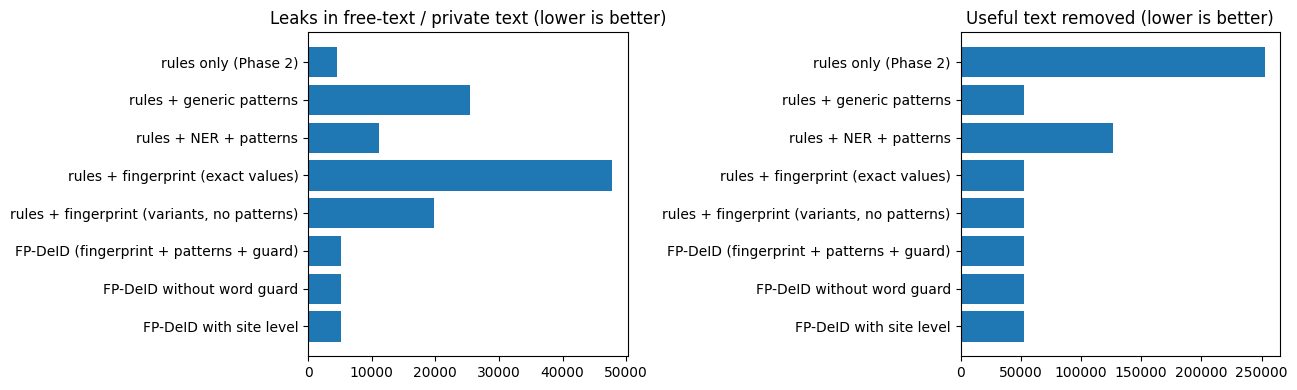

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
labels = [name.split(" ", 1)[1] for name in ablation_table.index]
axes[0].barh(labels, ablation_table["text leaks"].astype(float))
axes[0].set_title("Leaks in free-text / private text (lower is better)")
axes[0].invert_yaxis()
axes[1].barh(labels, ablation_table["text over-cleaned"].astype(float))
axes[1].set_title("Useful text removed (lower is better)")
axes[1].invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(phase_results, "ablation.png"), dpi=120)
plt.show()

## 3. The final version in detail

In [10]:
final_name = "6 FP-DeID (fingerprint + patterns + guard)"
final_db = os.path.join(scorer_out, "phase3_6", "validation_results.db")
results = scoring.add_categories(scoring.load_results(final_db))
results["passed"] = results["check_passed"].fillna(0).astype(float)

baselines_table = pd.read_csv(os.path.join(paths.RESULTS, "phase1", "baseline_scores.csv"), index_col=0)
compare = baselines_table[["BB"]].copy()
compare["Phase 2"] = pd.Series(ablation["1 rules only (Phase 2)"])
compare["Phase 3"] = pd.Series(ablation[final_name])
compare = compare.loc[["weighted_score_%", "hipaa_accuracy_%", "dicom_accuracy_%", "tcia_accuracy_%",
                       "privacy_failed", "utility_failed", "consistency_failed"]]
compare.to_csv(os.path.join(phase_results, "scores_vs_phase2.csv"))
compare

,BB,Phase 2,Phase 3
weighted_score_%,95.870,99.150,99.828
hipaa_accuracy_%,99.988,99.994,99.992
dicom_accuracy_%,99.885,100.000,100.000
tcia_accuracy_%,59.007,91.543,98.342
privacy_failed,31131.000,4577.000,5198.000
utility_failed,1458139.000,302210.000,55003.000
consistency_failed,32.000,0.000,0.000


In [11]:
per_action = scoring.per_action(results)
per_action.to_csv(os.path.join(phase_results, "per_action.csv"))
per_action

,checks,passed,failed,accuracy_%
action,,,,
<date_shifted>,139774,139774.0,0.0,100.000
<patid_consistent>,23921,23921.0,0.0,100.000
<pixels_hidden>,35,6.0,29.0,17.143
<pixels_retained>,23886,23886.0,0.0,100.000
<tag_retained>,1101091,1101090.0,1.0,100.000
<text_notnull>,618539,618539.0,0.0,100.000
<text_removed>,343583,338414.0,5169.0,98.496
<text_retained>,3453539,3398537.0,55002.0,98.407
<uid_changed>,234418,234418.0,0.0,100.000


In [12]:
per_modality = (results.groupby("modality")["passed"].mean() * 100).round(3)
per_modality.to_csv(os.path.join(phase_results, "per_modality.csv"))
per_modality

modality
<CR>    99.650
<CT>    99.801
<DX>    99.567
<MG>    99.979
<MR>    97.952
<PT>    99.084
<SR>    99.942
<US>    99.234
Name: passed, dtype: float64

### What did the fingerprint remove? (from the audit log, every removal names the entry it matched)

In [13]:
final_out = os.path.join(paths.OUTPUTS, "phase3_6")
found_by = collections.Counter()
fields_cleaned = collections.Counter()
n_cleaned = 0
n_explained = 0
with open(os.path.join(final_out, "audit.jsonl")) as f:
    for line in f:
        record = json.loads(line)
        for change in record["changes"]:
            if change["action"] != "F":
                continue
            n_cleaned = n_cleaned + 1
            removed_part = change["reason"].split("removed: ")[-1]
            if removed_part.strip() != "":
                n_explained = n_explained + 1
            for item in removed_part.split(", "):
                found_by[item] = found_by[item] + 1
            fields_cleaned[change["keyword"]] = fields_cleaned[change["keyword"]] + 1

print("text values cleaned:", n_cleaned, "| explained (linked to a fingerprint entry or pattern):",
      round(100 * n_explained / n_cleaned, 2), "%")
found_table = pd.Series(found_by).sort_values(ascending=False)
found_table.to_csv(os.path.join(phase_results, "removed_by_entry.csv"))
found_table.head(20)

text values cleaned: 162805 | explained (linked to a fingerprint entry or pattern): 100.0 %


name (PatientName)                     41073
pattern:doctor (generic)               38994
pattern:id (generic)                   25773
date (InstanceCreationDate)            21498
institution (InstitutionName)          20248
pattern:initials (generic)             14561
id (OtherPatientIDs)                   14517
pattern:phone (generic)                13203
address (PatientAddress)               13106
pattern:ssn (generic)                  10472
date (StudyDate)                        8219
pattern:date (generic)                  7770
pattern:site (generic)                  5454
pattern:address (generic)               2369
name (ReferringPhysicianName)            767
institution (ClinicalTrialSiteName)       60
id (ClinicalTrialSubjectReadingID)         6
id (PatientID)                             2
dtype: int64

In [14]:
pd.Series(fields_cleaned).sort_values(ascending=False).head(15)

StudyComments                        23308
AdditionalPatientHistory             23164
ProtocolName                         23144
SeriesDescription                    23124
RequestedProcedureDescription        23041
StudyDescription                     22709
PatientComments                       7652
MedicalAlerts                         4120
ScheduledProcedureStepDescription     3285
AcquisitionComments                   2992
RequestedProcedureComments            2941
Private tag data                      2894
ImageComments                          385
TextValue                               13
CommentsOnRadiationDose                 12
dtype: int64

## 4. Independent checks on the final output

In [15]:
# residual fingerprint hits: is the patient's own identity still anywhere in the output?
run_records = []
with open(os.path.join(final_out, "audit.jsonl")) as f:
    for line in f:
        record = json.loads(line)
        run_records.append((record["input"], record["output"], set(c["tag"] for c in record["changes"])))

patient_of = dict(zip(file_table["path"], file_table["patient_id"]))
residual_jobs = [(output, patient_of[input_path]) for input_path, output, logged in run_records]
start = time.time()
residual = checks.run_residual_check(residual_jobs, fingerprints, workers=16)
residual_table = pd.DataFrame(residual, columns=["tag", "category", "source", "file"])
print("checked in", round(time.time() - start), "s")
print("residual fingerprint hits:", len(residual_table))
if len(residual_table) > 0:
    print(residual_table.groupby(["tag", "category", "source"]).size().sort_values(ascending=False).head(15))
residual_table.drop(columns=["file"]).to_csv(os.path.join(phase_results, "residual_hits.csv"), index=False)

checked in 17 s
residual fingerprint hits: 0


In [16]:
# validity, audit coverage, research fields, dates, UIDs (same checks as Phase 2)
pairs = [(input_path, output) for input_path, output, logged in run_records]
valid_table = validity.check_pairs(pairs, workers=24)
valid_pct = 100 * (valid_table["new_errors"] == 0).mean()

uid_map = pd.read_csv(paths.VALIDATION_UID_MAP, dtype=str)
check_rows = checks.run_checks(run_records, set(uid_map["id_old"]), workers=16)
check_table = pd.DataFrame(check_rows)

independent = {
    "valid files %": round(valid_pct, 3),
    "audit coverage %": round(100 * (1 - check_table["changed_not_logged"].sum() / check_table["changed_paths"].sum()), 4),
    "research fields kept %": round(100 * check_table["utility_kept"].sum() / check_table["utility_present"].sum(), 4),
    "date intervals kept %": round(100 * check_table["date_pairs_same"].sum() / check_table["date_pairs"].sum(), 4),
    "original UIDs left": int(check_table["original_uids_left"].sum()),
}
pd.Series(independent)

valid files %             100.0
audit coverage %          100.0
research fields kept %    100.0
date intervals kept %     100.0
original UIDs left          0.0
dtype: float64

In [17]:
# extra time of the fingerprint per file (cleaning time of variant 6 vs. Phase 2 policy on the same files)
policy_rules = make_policy(os.path.join(paths.CONFIGS, "policy_phase2.yaml"))
timing_out = os.path.join(paths.OUTPUTS, "phase3_timing")
shutil.rmtree(timing_out, ignore_errors=True)
start = time.time()
engine.run(all_files, timing_out, policy_rules, workers=16)
rules_seconds = time.time() - start
shutil.rmtree(timing_out, ignore_errors=True)
final_seconds = ablation[final_name]["clean seconds"]
extra_ms = 1000 * (final_seconds - rules_seconds) * 16 / len(all_files)
print("rules only:", round(rules_seconds, 1), "s | with fingerprint:", final_seconds, "s")
print("extra time per file (one worker):", round(extra_ms, 2), "ms (+ fingerprint build", round(build_seconds, 1), "s once)")

rules only: 19.0 s | with fingerprint: 30.8 s
extra time per file (one worker): 7.88 ms (+ fingerprint build 14.6 s once)


## 5. Leaks and remaining failures, with causes

In [18]:
failed = results[results["passed"] < 1].copy()


def cause(row):
    tag_name = str(row["tag_name"])
    tag_ds = str(row["tag_ds"])
    if row["action"] == "<pixels_hidden>":
        return "burned-in text in pixels (Phase 4)"
    nested_private = tag_ds.count('"') >= 4
    if nested_private:
        return "private tag inside a private sequence: the scorer cannot read it (also fails for unchanged files)"
    is_private = tag_name.startswith("<[") or "Private" in tag_name
    if is_private and row["action"] == "<text_removed>":
        return "private value removed by TCIA's vendor knowledge base (not PHI)"
    if tag_name == "<Private Creator>":
        return "label of a private block whose content was binary and removed"
    if is_private and str(row["file_value"]) == "<>":
        return "private value empty in the input"
    if is_private and row["action"] == "<text_retained>" and str(row["file_value"]) == "None":
        return "private binary value removed (cannot be checked)"
    if "Palette" in tag_name or tag_name in ["<Rows>", "<Columns>", "<Bits Stored>", "<Bits Allocated>", "<High Bit>",
                                             "<Samples per Pixel>", "<Pixel Representation>",
                                             "<Photometric Interpretation>", "<Smallest Image Pixel Value>",
                                             "<Largest Image Pixel Value>"]:
        return "icon image removed on purpose (may show burned-in text)"
    if row["action"] == "<text_removed>":
        return "LEAK: identifier not found by fingerprint or patterns"
    if row["action"] == "<text_retained>" and tag_name in FREE_TEXT_NAMES:
        return "over-cleaning in free text"
    if is_private:
        return "over-cleaning in private text"
    return "other"


failed["cause"] = failed.apply(cause, axis=1)
cause_table = failed.groupby(["cause", "score_cat"]).size().unstack(fill_value=0)
cause_table["total"] = cause_table.sum(axis=1)
cause_table = cause_table.sort_values("total", ascending=False)
cause_table.to_csv(os.path.join(phase_results, "failures_by_cause.csv"))
cause_table

score_cat,dicom,hipaa,tcia,total
cause,,,,
private value empty in the input,0,0,39338,39338
private tag inside a private sequence: the scorer cannot read it (also fails for unchanged files),0,0,13686,13686
private value removed by TCIA's vendor knowledge base (not PHI),0,0,5130,5130
icon image removed on purpose (may show burned-in text),0,0,1763,1763
other,1,0,207,208
LEAK: identifier not found by fingerprint or patterns,0,17,22,39
burned-in text in pixels (Phase 4),0,29,0,29
over-cleaning in free text,0,0,8,8


In [19]:
# every leak, listed (tag and kind only; the synthetic values themselves stay out of git)
leaks = failed[failed["cause"].str.startswith("LEAK")]
leak_list = leaks.groupby(["tag_name", "modality"]).size().reset_index(name="checks")
leak_list.to_csv(os.path.join(phase_results, "leak_list.csv"), index=False)
print("leaks:", len(leaks))
leaks[["tag_name", "file_value", "answer_value"]].drop_duplicates("answer_value").head(20)

leaks: 39


,tag_name,file_value,answer_value
294390,<Image Comments>,<NONIONIC : 5932656543>,<NONIONIC : Margaret Williams : 5932656543>
1515797,<Text Value>,<RS>,<RS>
1578955,<Text Value>,<KM>,<KM>
1578963,<Text Value>,"<""1.4:Win32_081011"">","<""1.4:Win32_081011"">"
1579804,<Text Value>,<DL>,<DL>
6034822,<Patient Comments>,<<RegExProg>PROSTAAT\PROSTAAT\DETECTIE</RegExProg> : 2929551111>,<<RegExProg>PROSTAAT\PROSTAAT\DETECTIE</RegExProg> : Peter Phillips : 292955...


In [20]:
over = failed[failed["cause"].str.startswith("over-cleaning")]
print("over-cleaned checks:", len(over))
over[["tag_name", "file_value", "answer_value"]].drop_duplicates("answer_value").head(20)

over-cleaned checks: 8


,tag_name,file_value,answer_value
1578276,<Text Value>,"<""1.4:Win32_081011"">","<""1.4:Win32_081011"">"
1578515,<Text Value>,<V2D-1-60>,<QIBA_CT_1C-V2D-1-60>
1578527,<Text Value>,<V 60>,<QIBA_CT_1C V 60>
1579364,<Text Value>,<V6C-2-6>,<QIBA_CT_1C-V6C-2-6>
1579376,<Text Value>,<V 6>,<QIBA_CT_1C V 6>


## 6. Phase 3 summary vs. pass criteria

In [21]:
final = ablation[final_name]
ner = ablation["3 rules + NER + patterns"]
criteria = pd.DataFrame([
    ["MIDI-B weighted score (validation)", "≥ 99%", final["weighted_score_%"]],
    ["residual fingerprint hits in output", "0", len(residual_table)],
    ["leaks in free text / private text", "0, or each listed with a cause", final["text leaks"]],
    ["fingerprint vs NER: text leaks", "≤ NER (" + str(ner["text leaks"]) + ")", final["text leaks"]],
    ["fingerprint vs NER: useful text removed", "≤ NER (" + str(ner["text over-cleaned"]) + ")", final["text over-cleaned"]],
    ["removals explained by an entry/pattern", "100%", round(100 * n_explained / n_cleaned, 2)],
    ["extra time per file", "≤ 20 ms", round(extra_ms, 2)],
    ["valid DICOM", "100%", independent["valid files %"]],
    ["audit coverage", "100%", independent["audit coverage %"]],
    ["research fields kept", "100%", independent["research fields kept %"]],
], columns=["check", "target", "result"])
criteria.to_csv(os.path.join(phase_results, "pass_criteria.csv"), index=False)
criteria

,check,target,result
0,MIDI-B weighted score (validation),≥ 99%,99.828
1,residual fingerprint hits in output,0,0.000
2,leaks in free text / private text,"0, or each listed with a cause",5169.000
3,fingerprint vs NER: text leaks,≤ NER (11090),5169.000
4,fingerprint vs NER: useful text removed,≤ NER (126512),53032.000
5,removals explained by an entry/pattern,100%,100.000
6,extra time per file,≤ 20 ms,7.880
7,valid DICOM,100%,100.000
8,audit coverage,100%,100.000
9,research fields kept,100%,100.000


In [22]:
# save the audit log (compressed) and free the disk
import gzip

with open(os.path.join(final_out, "audit.jsonl"), "rb") as source:
    with gzip.open(os.path.join(paths.DERIVED, "phase3_audit.jsonl.gz"), "wb") as target:
        shutil.copyfileobj(source, target)
with open(os.path.join(paths.DERIVED, "fingerprints_validation.pkl"), "wb") as f:
    pickle.dump((fingerprints, common_words), f)
shutil.rmtree(final_out, ignore_errors=True)
print("done")

done
